1(b)i I use median imputation. I calculate the median from the training set and use it to replace missing values in both the training and test sets.

In [2]:
import pandas as pd
from sklearn.impute import SimpleImputer

# Skip the introductory text and recognize "na" as missing values
train = pd.read_csv(
    "../data/Homework 6 Data/aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)

test = pd.read_csv(
    "../data/Homework 6 Data/aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)

# Separate features and labels
X_train_raw = train.drop(columns="class")
X_test_raw = test.drop(columns="class")

y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})

print("Training missing before:", X_train_raw.isna().sum().sum())
print("Test missing before:", X_test_raw.isna().sum().sum())

# Learn medians from the training set and impute both sets
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Training missing after:", X_train.isna().sum().sum())
print("Test missing after:", X_test.isna().sum().sum())

Training missing before: 850015
Test missing before: 228680
Training missing after: 0
Test missing after: 0


1(b)ii

In [3]:
# Calculate the mean, sample standard deviation, and CV
cv_table = pd.DataFrame({
    "Mean": X_train.mean(),
    "Std": X_train.std(ddof=1)
})

# CV is undefined when the mean is zero
cv_table["CV"] = cv_table["Std"] / cv_table["Mean"].replace(0, float("nan"))

1(b)iii

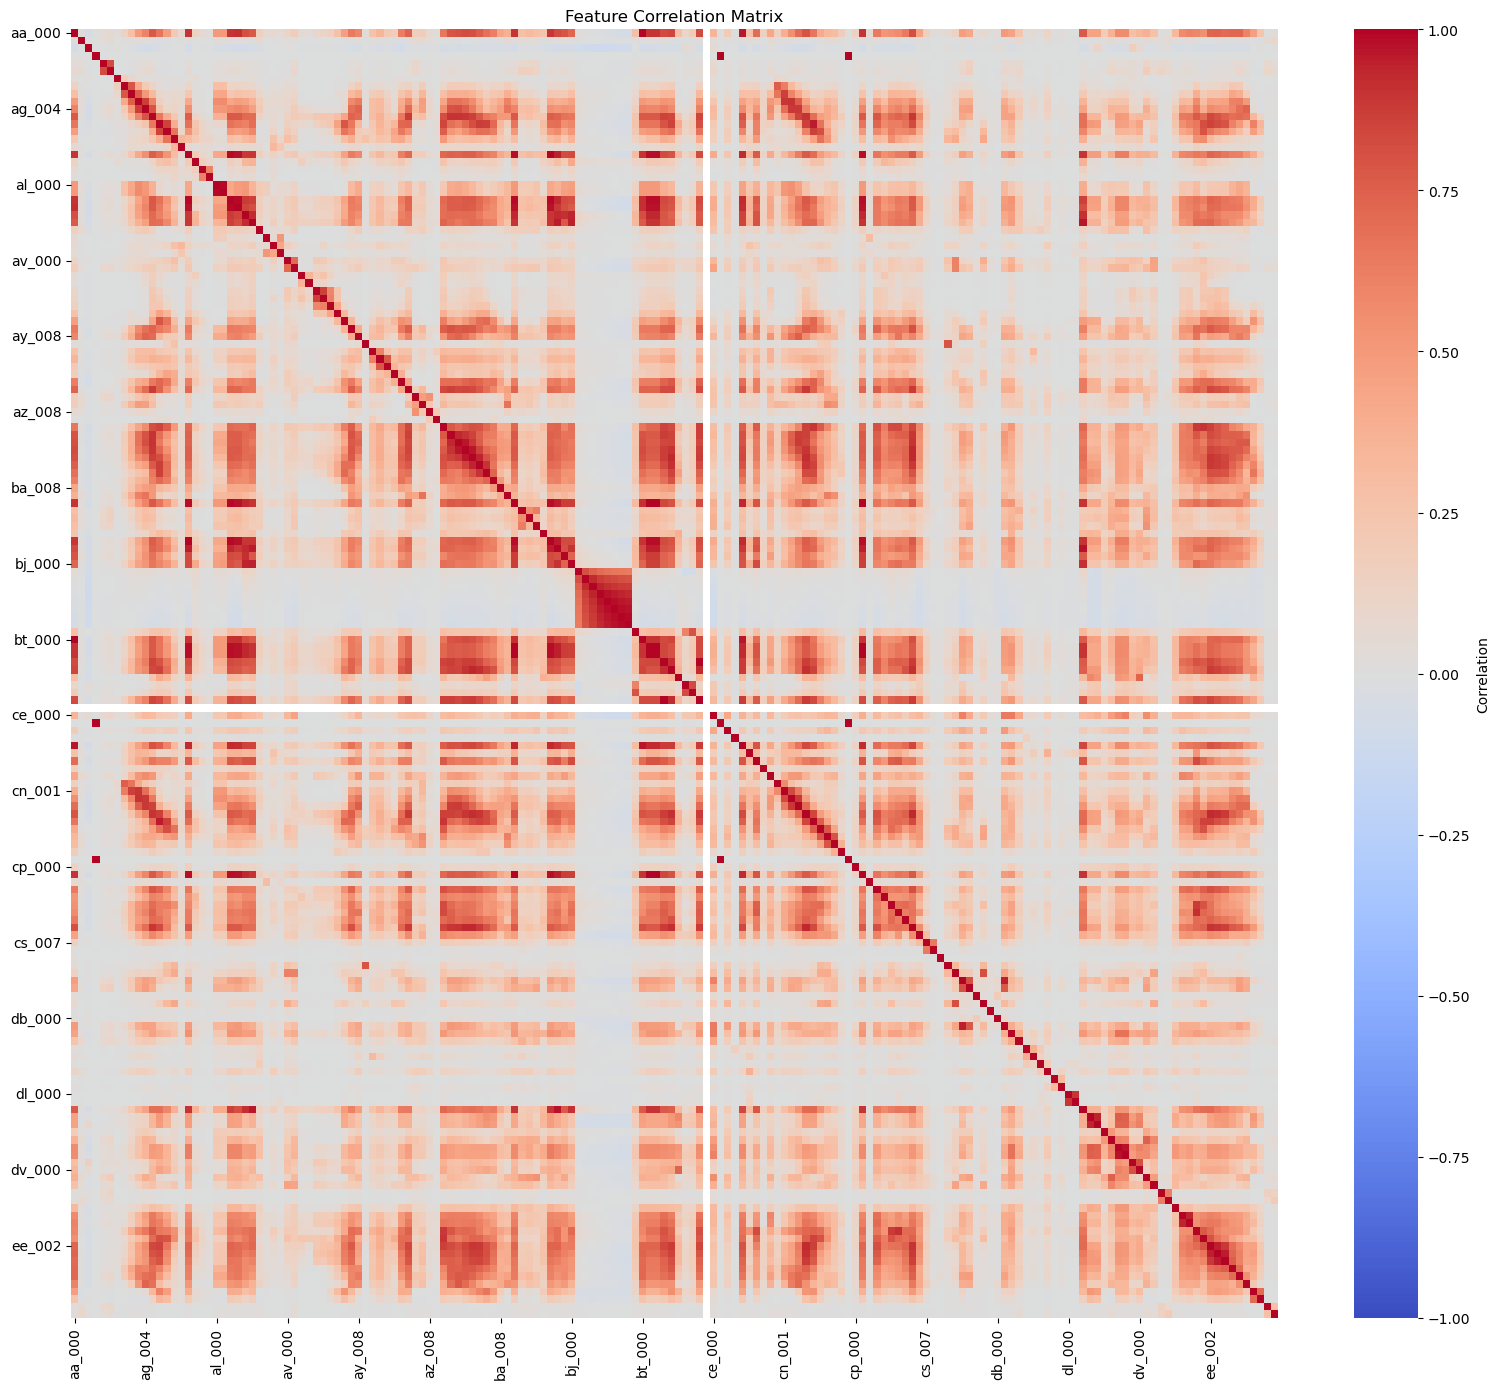

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the Pearson correlation matrix
corr_matrix = X_train.corr()

# Plot the correlation heatmap
plt.figure(figsize=(16, 14))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10,
    cbar_kws={"label": "Correlation"}
)

plt.title("Feature Correlation Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

1(b)iv

Scatter plots can suggest correlations, but they cannot directly establish statistical significance.

,Mean,Std,CV
cf_000,143107.5341,3.504525e+07,244.8875
co_000,143330.0177,3.504525e+07,244.5074
ad_000,143438.2921,3.504525e+07,244.3228
cs_009,770.5097,1.833278e+05,237.9306
dh_000,4392.6408,5.412441e+05,123.2161
dj_000,37.2713,4.379166e+03,117.4942
ag_000,219.1577,2.036364e+04,92.9178
as_000,125.4079,1.095219e+04,87.3325
ay_009,1149.6196,9.741156e+04,84.7337
ak_000,907.6607,7.299859e+04,80.4250


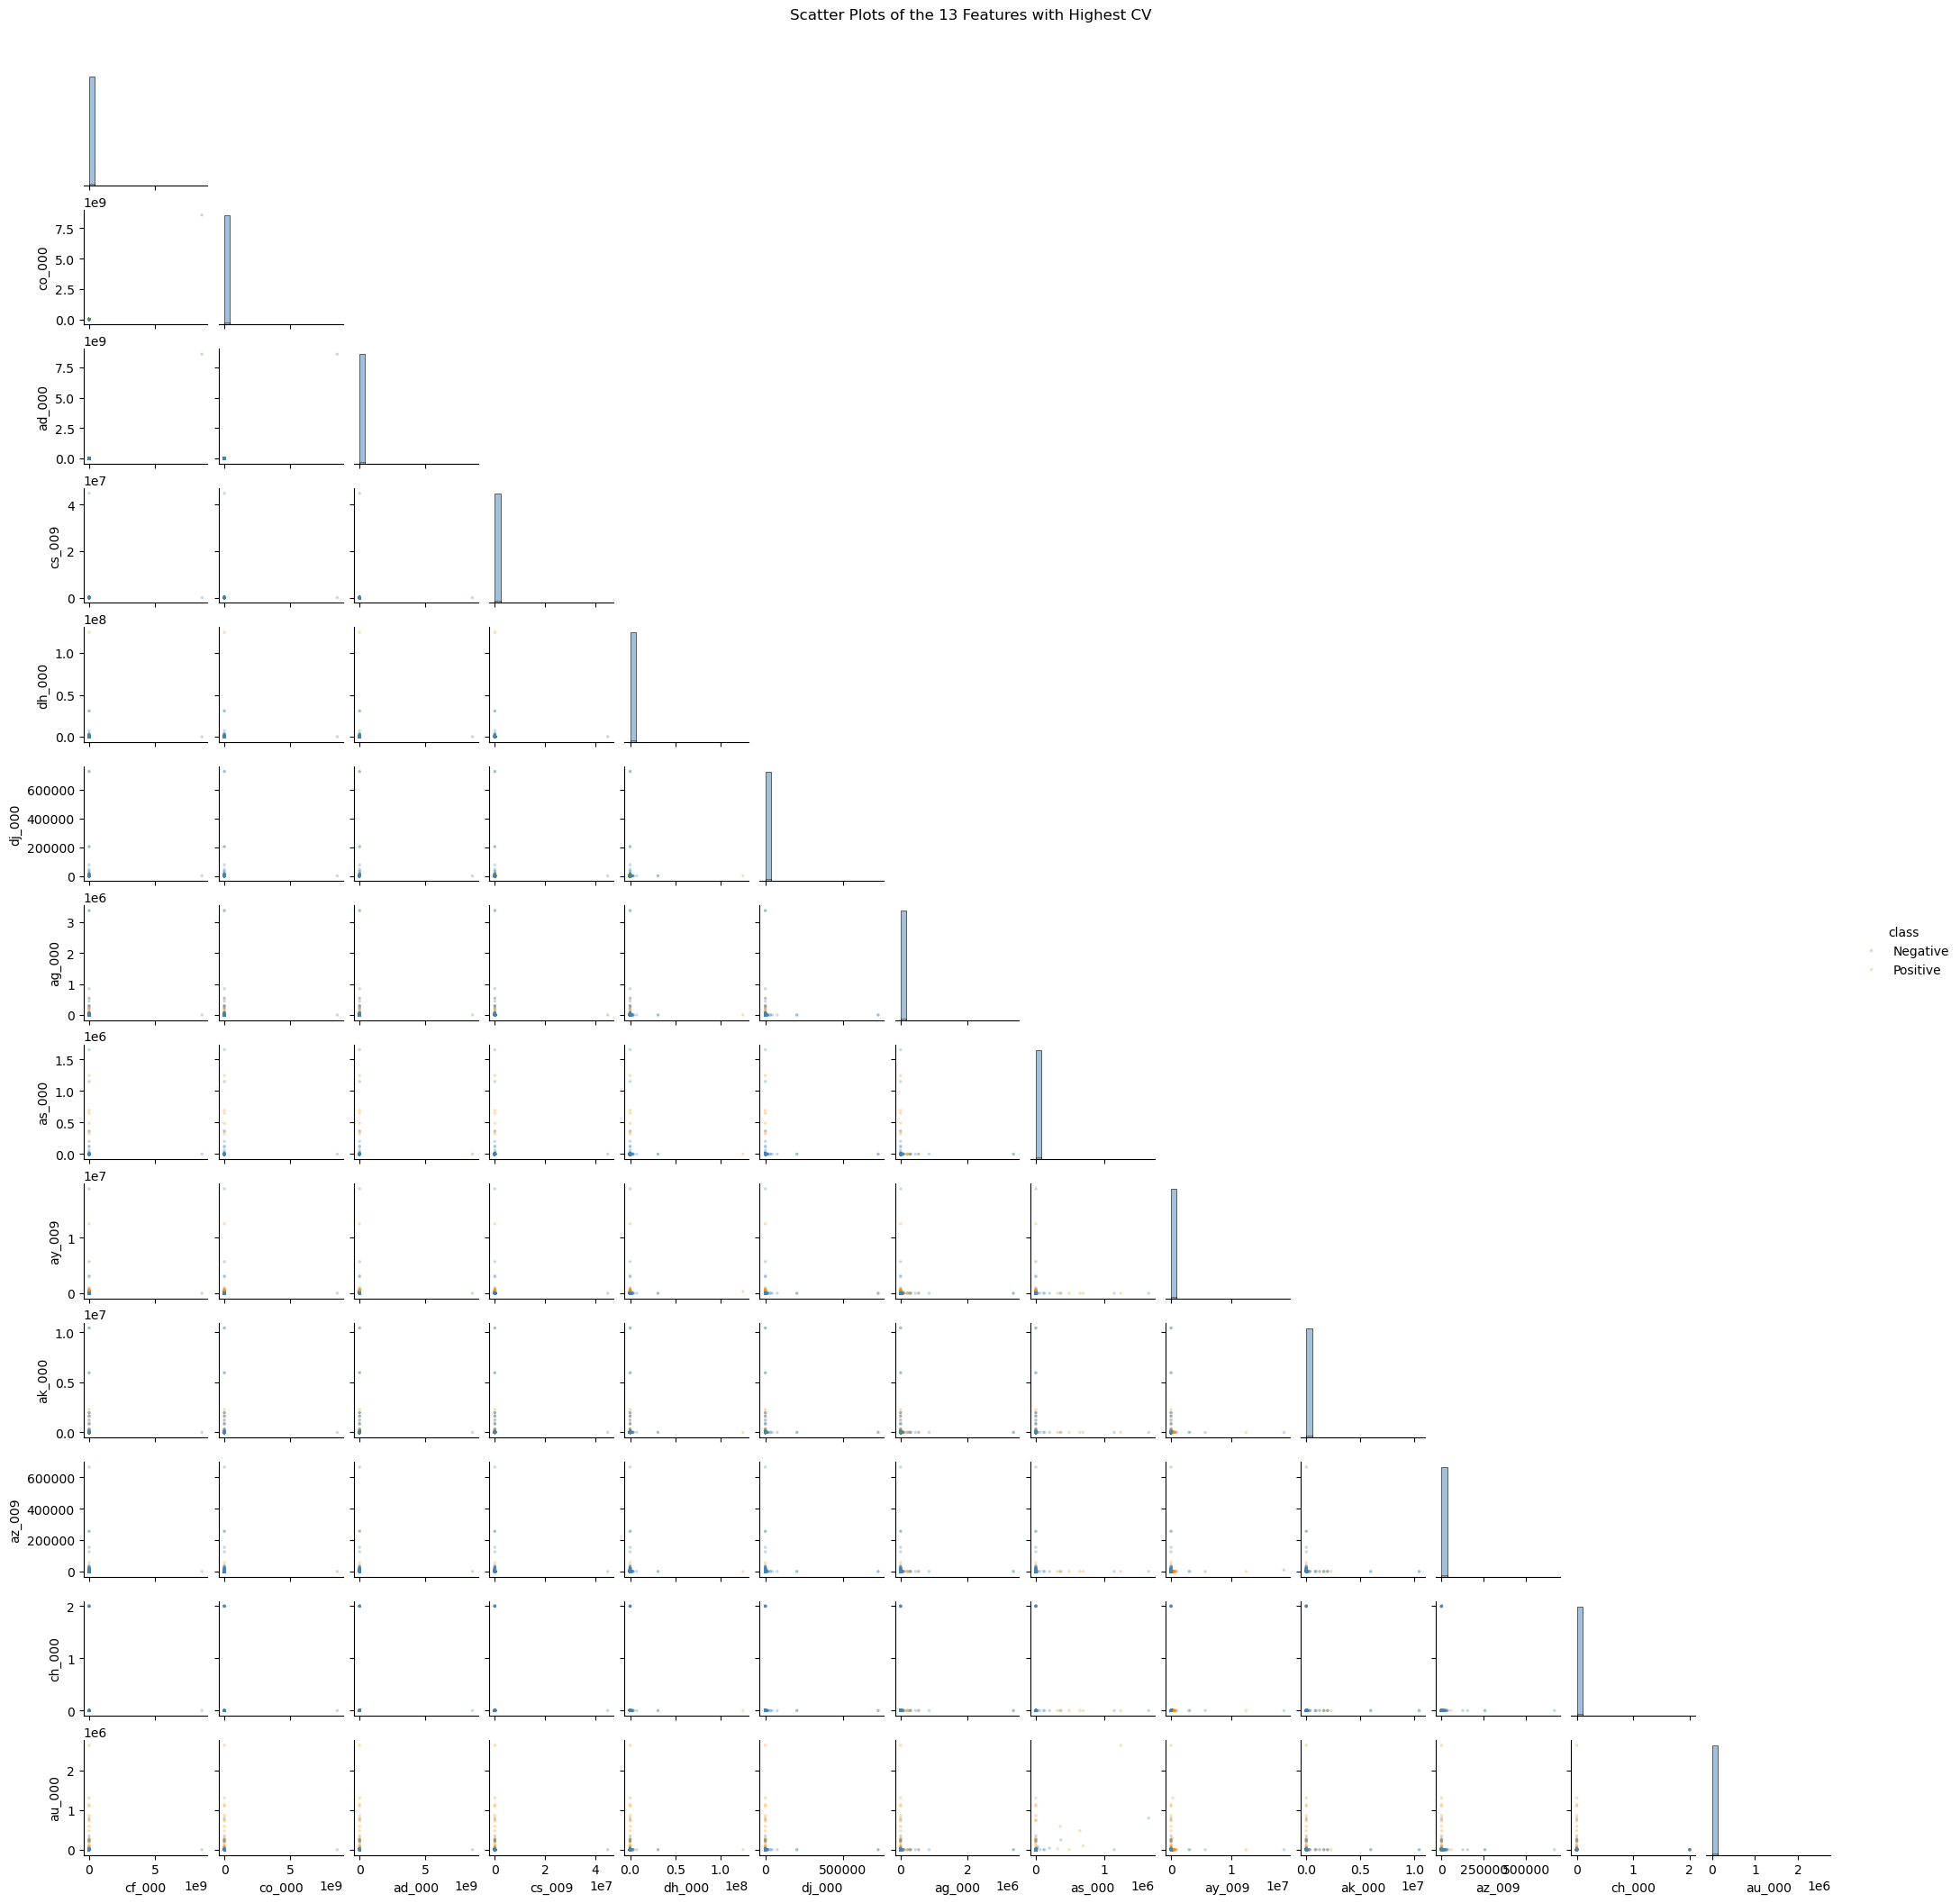

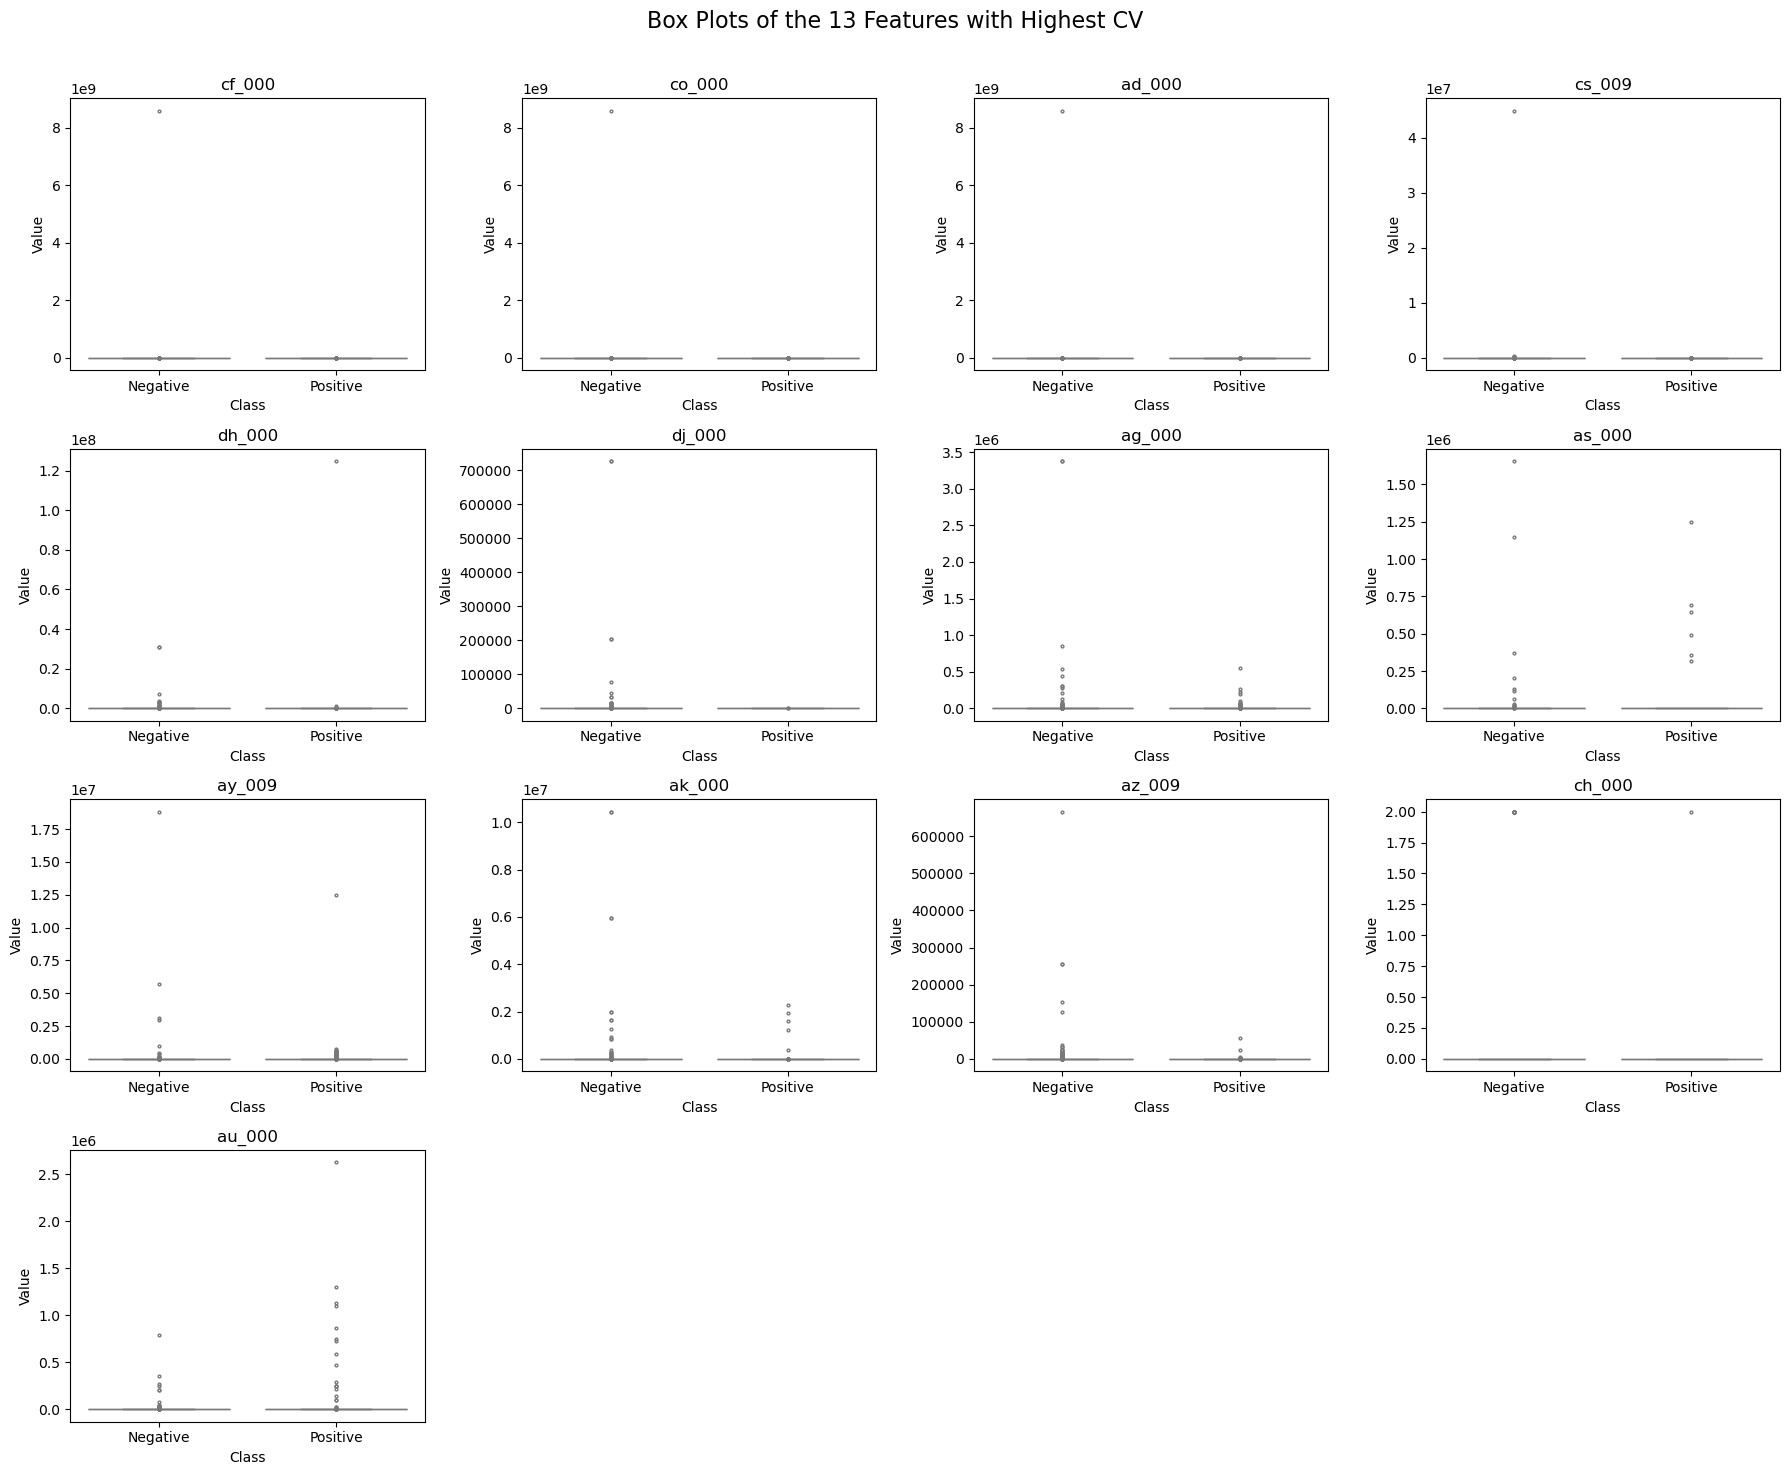

In [5]:
import numpy as np

# Select the 13 features with the highest CV
n_features = int(np.sqrt(X_train.shape[1]))
top_features = cv_table["CV"].nlargest(n_features).index.tolist()

display(cv_table.loc[top_features].round(4))

# Prepare training data for visualization
plot_data = X_train[top_features].copy()
plot_data["class"] = y_train.map({0: "Negative", 1: "Positive"})

g = sns.pairplot(
    data=plot_data,
    vars=top_features,
    hue="class",
    hue_order=["Negative", "Positive"],
    palette={"Negative": "steelblue", "Positive": "darkorange"},
    corner=True,
    diag_kind="hist",
    height=1.6,
    plot_kws={"s": 6, "alpha": 0.3, "linewidth": 0},
    diag_kws={"bins": 20}
)

g.fig.suptitle("Scatter Plots of the 13 Features with Highest CV", y=1.02)
plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 15))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        data=plot_data,
        x="class",
        y=feature,
        order=["Negative", "Positive"],
        color="lightblue",
        fliersize=2,
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel("Value")

# Remove unused subplots
for ax in axes[len(top_features):]:
    ax.remove()

fig.suptitle("Box Plots of the 13 Features with Highest CV", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

1(b)v

The training set contains 1,000 positive samples and 59,000 negative samples. It is highly imbalanced, with a negative-to-positive ratio of 59:1.

1(c)

,Misclassification Rate,AUC
Training,0.000017,1.000000
Test,0.007563,0.992745


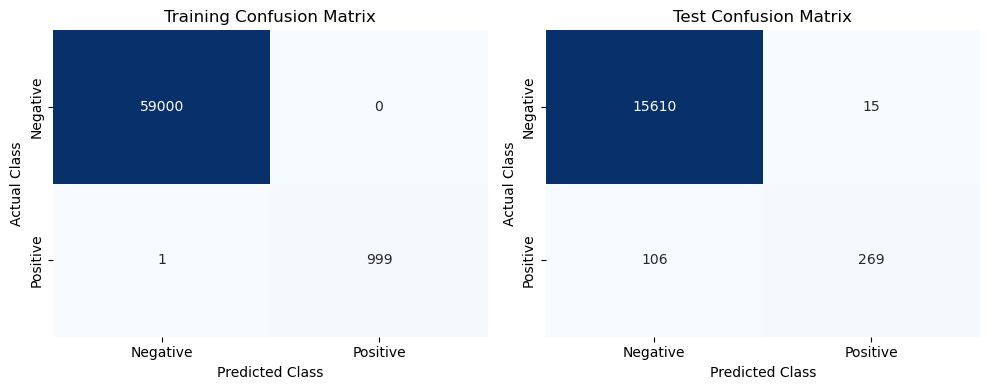

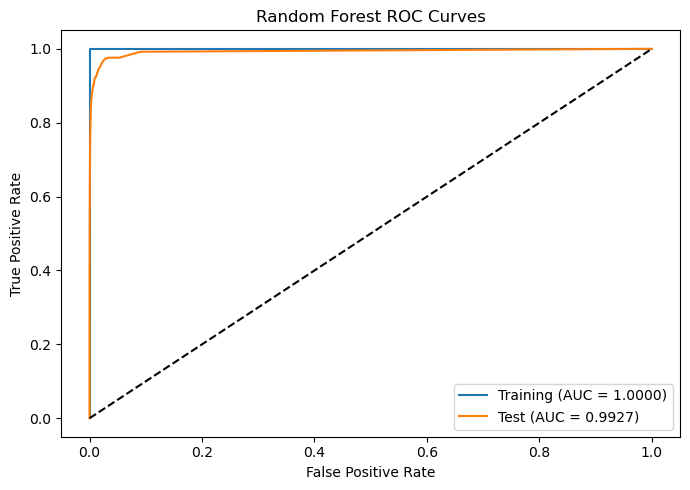

OOB error: 0.6167%
Test error: 0.7563%


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, confusion_matrix, roc_auc_score, roc_curve
)

rf = RandomForestClassifier(
    n_estimators=100,
    class_weight=None,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Predicted classes
train_pred = rf.predict(X_train)
test_pred = rf.predict(X_test)

# Predicted probabilities of the positive class
train_prob = rf.predict_proba(X_train)[:, 1]
test_prob = rf.predict_proba(X_test)[:, 1]

# Misclassification rates and AUC
train_error = 1 - accuracy_score(y_train, train_pred)
test_error = 1 - accuracy_score(y_test, test_pred)

train_auc = roc_auc_score(y_train, train_prob)
test_auc = roc_auc_score(y_test, test_prob)

results = pd.DataFrame({
    "Misclassification Rate": [train_error, test_error],
    "AUC": [train_auc, test_auc]
}, index=["Training", "Test"])

display(results.round(6))

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, y_true, y_pred, title in [
    (axes[0], y_train, train_pred, "Training"),
    (axes[1], y_test, test_pred, "Test")
]:
    sns.heatmap(
        confusion_matrix(y_true, y_pred, labels=[0, 1]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )
    ax.set_title(f"{title} Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))

for y_true, y_prob, name in [
    (y_train, train_prob, "Training"),
    (y_test, test_prob, "Test")
]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.4f})")

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.tight_layout()
plt.show()

oob_error = 1 - rf.oob_score_

print(f"OOB error: {oob_error:.4%}")
print(f"Test error: {test_error:.4%}")

1(d) 

I use class weighting to address class imbalance.

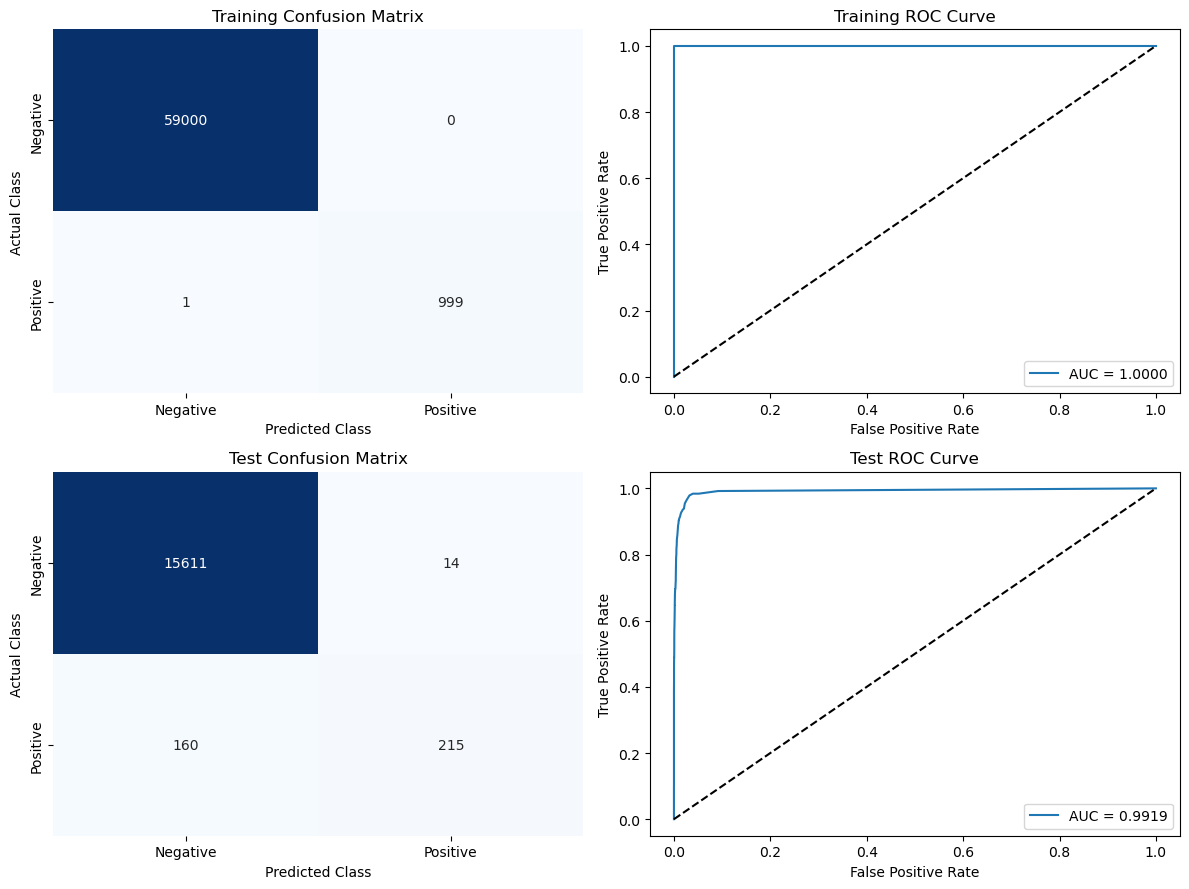

,Unweighted RF,Balanced RF
Training Error,0.000017,0.000017
Test Error,0.007563,0.010875
Training AUC,1.000000,1.000000
Test AUC,0.992745,0.991944
OOB Error,0.006167,0.008200
Test Positive Recall,0.717333,0.573333


In [7]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)

train_pred_bal = rf_balanced.predict(X_train)
test_pred_bal = rf_balanced.predict(X_test)

train_prob_bal = rf_balanced.predict_proba(X_train)[:, 1]
test_prob_bal = rf_balanced.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, (name, y_true, y_pred, y_prob) in enumerate([
    ("Training", y_train, train_pred_bal, train_prob_bal),
    ("Test", y_test, test_pred_bal, test_prob_bal)
]):
    # Confusion matrix
    sns.heatmap(
        confusion_matrix(y_true, y_pred, labels=[0, 1]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{name} Confusion Matrix")
    axes[i, 0].set_xlabel("Predicted Class")
    axes[i, 0].set_ylabel("Actual Class")

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    axes[i, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[i, 1].plot([0, 1], [0, 1], "k--")
    axes[i, 1].set_title(f"{name} ROC Curve")
    axes[i, 1].set_xlabel("False Positive Rate")
    axes[i, 1].set_ylabel("True Positive Rate")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

from sklearn.metrics import recall_score

comparison = pd.DataFrame({
    "Unweighted RF": [
        train_error,
        test_error,
        train_auc,
        test_auc,
        1 - rf.oob_score_,
        recall_score(y_test, test_pred)
    ],
    "Balanced RF": [
        1 - accuracy_score(y_train, train_pred_bal),
        1 - accuracy_score(y_test, test_pred_bal),
        roc_auc_score(y_train, train_prob_bal),
        roc_auc_score(y_test, test_prob_bal),
        1 - rf_balanced.oob_score_,
        recall_score(y_test, test_pred_bal)
    ]
}, index=[
    "Training Error",
    "Test Error",
    "Training AUC",
    "Test AUC",
    "OOB Error",
    "Test Positive Recall"
])

display(comparison.round(6))

Compared with the unweighted model, the weighted model increases test error from 0.7563% to 1.0875% and reduces positive-class recall from 71.73% to 57.33%. Test AUC also decreases slightly, from 0.9927 to 0.9919. Its OOB error is 0.8200%, lower than its test error of 1.0875%. Therefore, class weighting does not improve performance in this experiment.

1(e)

c:\Code\Anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [07:14:49] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  bst.update(dtrain, iteration=i, fobj=obj)


Best alpha: 1e-05
CV error: 0.9433%


,Alpha,CV Error,CV AUC
0,0.00001,0.009433,0.973292
1,0.00010,0.009483,0.975452
2,0.00100,0.010383,0.979726
3,0.01000,0.014050,0.979573
4,0.10000,0.016667,0.500000


c:\Code\Anaconda3\Lib\site-packages\xgboost\core.py:569: UserWarning: [07:15:12] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  return func(**kwargs)


,Misclassification Rate,AUC
Training,0.008883,0.980253
Test,0.011687,0.982692


CV error: 0.9433%
Test error: 1.1687%
Test error - CV error: 0.2254 percentage points


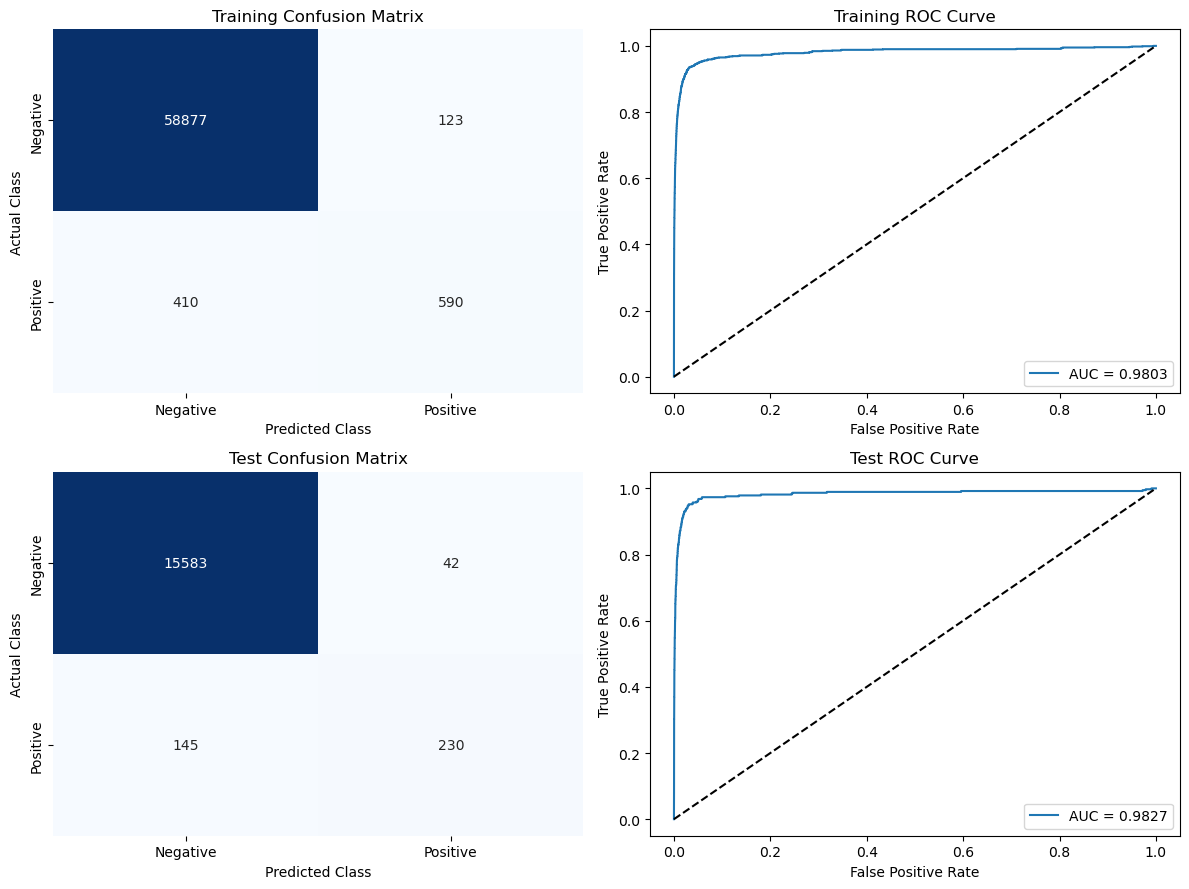

In [9]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold

xgb_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("xgb", XGBClassifier(
        booster="gblinear",
        objective="binary:logistic",
        reg_lambda=0,
        n_estimators=500,
        learning_rate=0.01,
        updater="coord_descent",
        feature_selector="cyclic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "xgb__reg_alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring={"accuracy": "accuracy", "auc": "roc_auc"},
    refit="accuracy",
    cv=cv,
    n_jobs=5,
    error_score="raise"
)

xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_
best_alpha = xgb_search.best_params_["xgb__reg_alpha"]
cv_error_xgb = 1 - xgb_search.best_score_

print("Best alpha:", best_alpha)
print(f"CV error: {cv_error_xgb:.4%}")

cv_results = pd.DataFrame({
    "Alpha": xgb_search.cv_results_["param_xgb__reg_alpha"],
    "CV Error": 1 - xgb_search.cv_results_["mean_test_accuracy"],
    "CV AUC": xgb_search.cv_results_["mean_test_auc"]
})

display(cv_results)

# Predict classes and positive-class probabilities
train_pred_xgb = best_xgb.predict(X_train)
test_pred_xgb = best_xgb.predict(X_test)

train_prob_xgb = best_xgb.predict_proba(X_train)[:, 1]
test_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

# Calculate misclassification rates and AUC
train_error_xgb = 1 - accuracy_score(y_train, train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test, test_pred_xgb)

train_auc_xgb = roc_auc_score(y_train, train_prob_xgb)
test_auc_xgb = roc_auc_score(y_test, test_prob_xgb)

results_xgb = pd.DataFrame({
    "Misclassification Rate": [train_error_xgb, test_error_xgb],
    "AUC": [train_auc_xgb, test_auc_xgb]
}, index=["Training", "Test"])

display(results_xgb.round(6))

print(f"CV error: {cv_error_xgb:.4%}")
print(f"Test error: {test_error_xgb:.4%}")
print(
    f"Test error - CV error: "
    f"{100 * (test_error_xgb - cv_error_xgb):.4f} percentage points"
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, (name, y_true, y_pred, y_prob) in enumerate([
    ("Training", y_train, train_pred_xgb, train_prob_xgb),
    ("Test", y_test, test_pred_xgb, test_prob_xgb)
]):
    # Confusion matrix
    sns.heatmap(
        confusion_matrix(y_true, y_pred, labels=[0, 1]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{name} Confusion Matrix")
    axes[i, 0].set_xlabel("Predicted Class")
    axes[i, 0].set_ylabel("Actual Class")

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    axes[i, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[i, 1].plot([0, 1], [0, 1], "k--")
    axes[i, 1].set_title(f"{name} ROC Curve")
    axes[i, 1].set_xlabel("False Positive Rate")
    axes[i, 1].set_ylabel("True Positive Rate")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()


1(f)

c:\Code\Anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [07:50:04] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  bst.update(dtrain, iteration=i, fobj=obj)


Best alpha: 1e-05
CV error: 2.4300%


,Alpha,CV Error,CV AUC
0,0.00001,0.024300,0.970741
1,0.00010,0.024300,0.971675
2,0.00100,0.025017,0.977743
3,0.01000,0.030767,0.980715
4,0.10000,0.030950,0.977406


c:\Code\Anaconda3\Lib\site-packages\xgboost\core.py:569: UserWarning: [07:50:49] WARNING: C:\Users\task_179016205368646\croot\xgboost-split_1790162376793\work\src\learner.cc:825: `booster=gblinear` is deprecated and support will be removed in a future release.
  return func(**kwargs)


,Without SMOTE,With SMOTE
Best Alpha,0.000010,0.000010
CV Error,0.009433,0.024300
Training Error,0.008883,0.023533
Test Error,0.011687,0.023188
Training AUC,0.980253,0.988895
Test AUC,0.982692,0.990668
Test Positive Recall,0.613333,0.936000


SMOTE CV error: 2.4300%
SMOTE test error: 2.3188%
Test error - CV error: -0.1112 percentage points


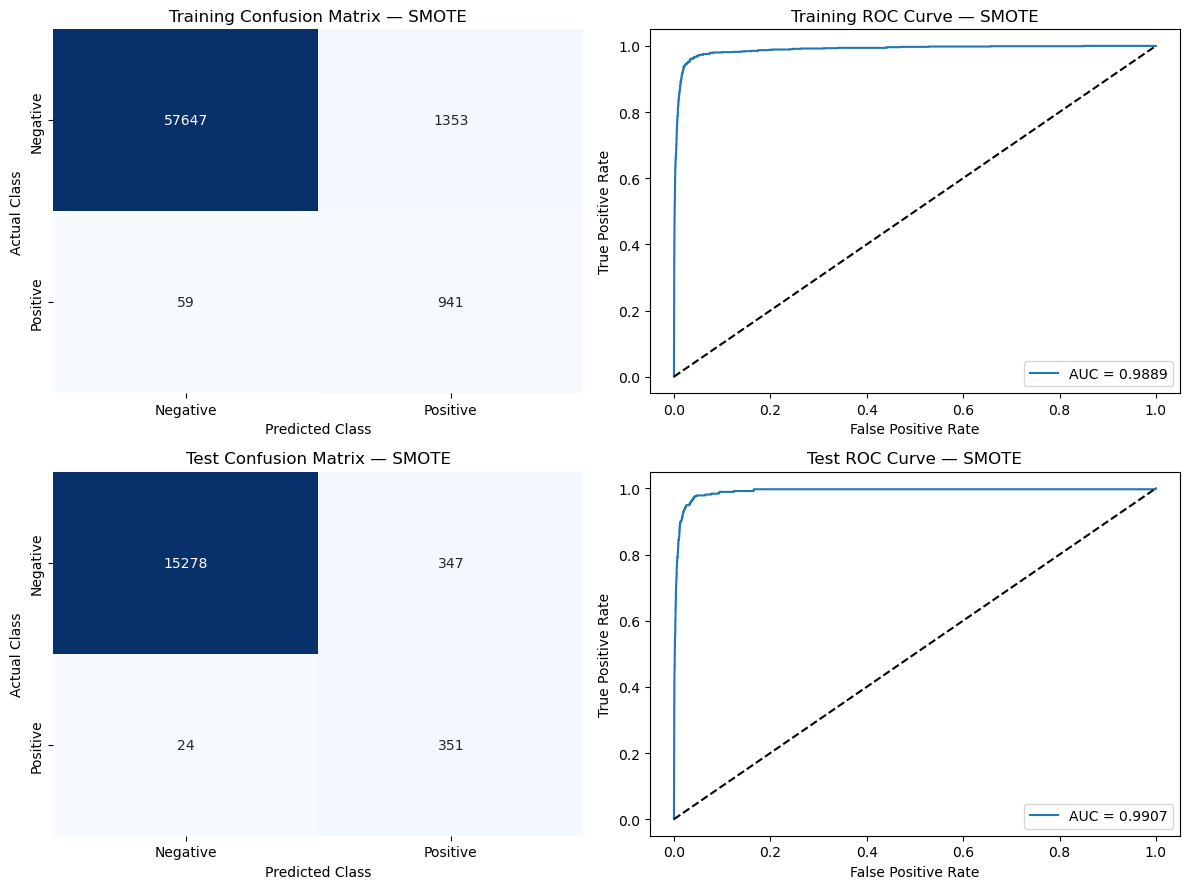

In [11]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("xgb", XGBClassifier(
        booster="gblinear",
        objective="binary:logistic",
        reg_lambda=0,
        n_estimators=500,
        learning_rate=0.01,
        updater="coord_descent",
        feature_selector="cyclic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

# Use the same alpha candidates and CV folds as in part (e)
smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=param_grid,
    scoring={"accuracy": "accuracy", "auc": "roc_auc"},
    refit="accuracy",
    cv=cv,
    n_jobs=5,
    error_score="raise"
)

smote_search.fit(X_train, y_train)

best_smote = smote_search.best_estimator_
best_alpha_smote = smote_search.best_params_["xgb__reg_alpha"]
cv_error_smote = 1 - smote_search.best_score_

print("Best alpha:", best_alpha_smote)
print(f"CV error: {cv_error_smote:.4%}")

smote_cv_results = pd.DataFrame({
    "Alpha": smote_search.cv_results_["param_xgb__reg_alpha"],
    "CV Error": 1 - smote_search.cv_results_["mean_test_accuracy"],
    "CV AUC": smote_search.cv_results_["mean_test_auc"]
})

display(smote_cv_results)

from sklearn.metrics import recall_score

# Evaluate on the original training and test samples
train_pred_smote = best_smote.predict(X_train)
test_pred_smote = best_smote.predict(X_test)

train_prob_smote = best_smote.predict_proba(X_train)[:, 1]
test_prob_smote = best_smote.predict_proba(X_test)[:, 1]

train_error_smote = 1 - accuracy_score(y_train, train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test, test_pred_smote)

train_auc_smote = roc_auc_score(y_train, train_prob_smote)
test_auc_smote = roc_auc_score(y_test, test_prob_smote)

recall_xgb = recall_score(y_test, test_pred_xgb)
recall_smote = recall_score(y_test, test_pred_smote)

comparison_xgb = pd.DataFrame({
    "Without SMOTE": [
        best_alpha,
        cv_error_xgb,
        train_error_xgb,
        test_error_xgb,
        train_auc_xgb,
        test_auc_xgb,
        recall_xgb
    ],
    "With SMOTE": [
        best_alpha_smote,
        cv_error_smote,
        train_error_smote,
        test_error_smote,
        train_auc_smote,
        test_auc_smote,
        recall_smote
    ]
}, index=[
    "Best Alpha",
    "CV Error",
    "Training Error",
    "Test Error",
    "Training AUC",
    "Test AUC",
    "Test Positive Recall"
])

display(comparison_xgb.round(6))

print(f"SMOTE CV error: {cv_error_smote:.4%}")
print(f"SMOTE test error: {test_error_smote:.4%}")
print(
    f"Test error - CV error: "
    f"{100 * (test_error_smote - cv_error_smote):.4f} percentage points"
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for i, (name, y_true, y_pred, y_prob) in enumerate([
    ("Training", y_train, train_pred_smote, train_prob_smote),
    ("Test", y_test, test_pred_smote, test_prob_smote)
]):
    # Confusion matrix
    sns.heatmap(
        confusion_matrix(y_true, y_pred, labels=[0, 1]),
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{name} Confusion Matrix — SMOTE")
    axes[i, 0].set_xlabel("Predicted Class")
    axes[i, 0].set_ylabel("Actual Class")

    # ROC curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    axes[i, 1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    axes[i, 1].plot([0, 1], [0, 1], "k--")
    axes[i, 1].set_title(f"{name} ROC Curve — SMOTE")
    axes[i, 1].set_xlabel("False Positive Rate")
    axes[i, 1].set_ylabel("True Positive Rate")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

Although SMOTE slightly increases the misclassification rate, it substantially improves positive-class detection and also increases AUC.

2

(a) iv. Training RSS decreases as s increases because the constraint becomes less restrictive, allowing a closer fit to the training data.

(b) ii. Test RSS typically decreases initially as reduced bias improves prediction, then increases as greater variance leads to overfitting.

(c) iii. Variance generally increases because a more flexible model is more sensitive to changes in the training data.

(d) iv. Squared bias generally decreases because the weaker constraint allows the model to better approximate the underlying relationship.

(e) v. Irreducible error remains constant because it comes from random noise in the data and does not depend on s.

3

Assume $\lambda>0$. Since the data are centered, $\hat{\beta}_0=0$.

**(a)** The ridge regression optimization problem is

$$
\min_{\beta_1,\beta_2}
(y_1-x_{11}\beta_1-x_{12}\beta_2)^2
+(y_2-x_{21}\beta_1-x_{22}\beta_2)^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b)** The loss Function is

$$
RSS+\lambda(\beta_1^2+\beta_2^2),\qquad \lambda>0
$$

Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$

$$
RSS=(y_1-x_{11}(\beta_1+\beta_2))^2
+(y_2-x_{21}(\beta_1+\beta_2))^2.
$$

It can be seen that the RSS depends only on the sum $t=\beta_1+\beta_2$. For a fixed $t$,

$$
\beta_1^2+\beta_2^2
=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
$$

The ridge penalty is minimized when $\beta_1=\beta_2$. Therefore,

$$
\hat{\beta}_1=\hat{\beta}_2.
$$

**(c)** The lasso optimization problem is

$$
\min_{\beta_1,\beta_2}
(y_1-x_{11}\beta_1-x_{12}\beta_2)^2
+(y_2-x_{21}\beta_1-x_{22}\beta_2)^2
+\lambda(|\beta_1|+|\beta_2|).
$$

**(d)** The RSS again depends only on $\beta_1+\beta_2$. Also,

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|,
$$

with equality when the coefficients have the same sign or one is zero.

Let $t^*$ be the optimal coefficient sum. Every pair

$$
\hat{\beta}_1=a t^*, \qquad
\hat{\beta}_2=(1-a)t^*, \qquad 0\leq a\leq1
$$



4

Majority vote: Using a threshold of 0.5, six trees predict Red and four predict Green. Therefore, the final classification is Red.

Average probability: The average predicted probability of Red is

$$
\bar p=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=\frac{4.5}{10}=0.45.
$$

Since $0.45<0.5$, the final classification is Green.

5
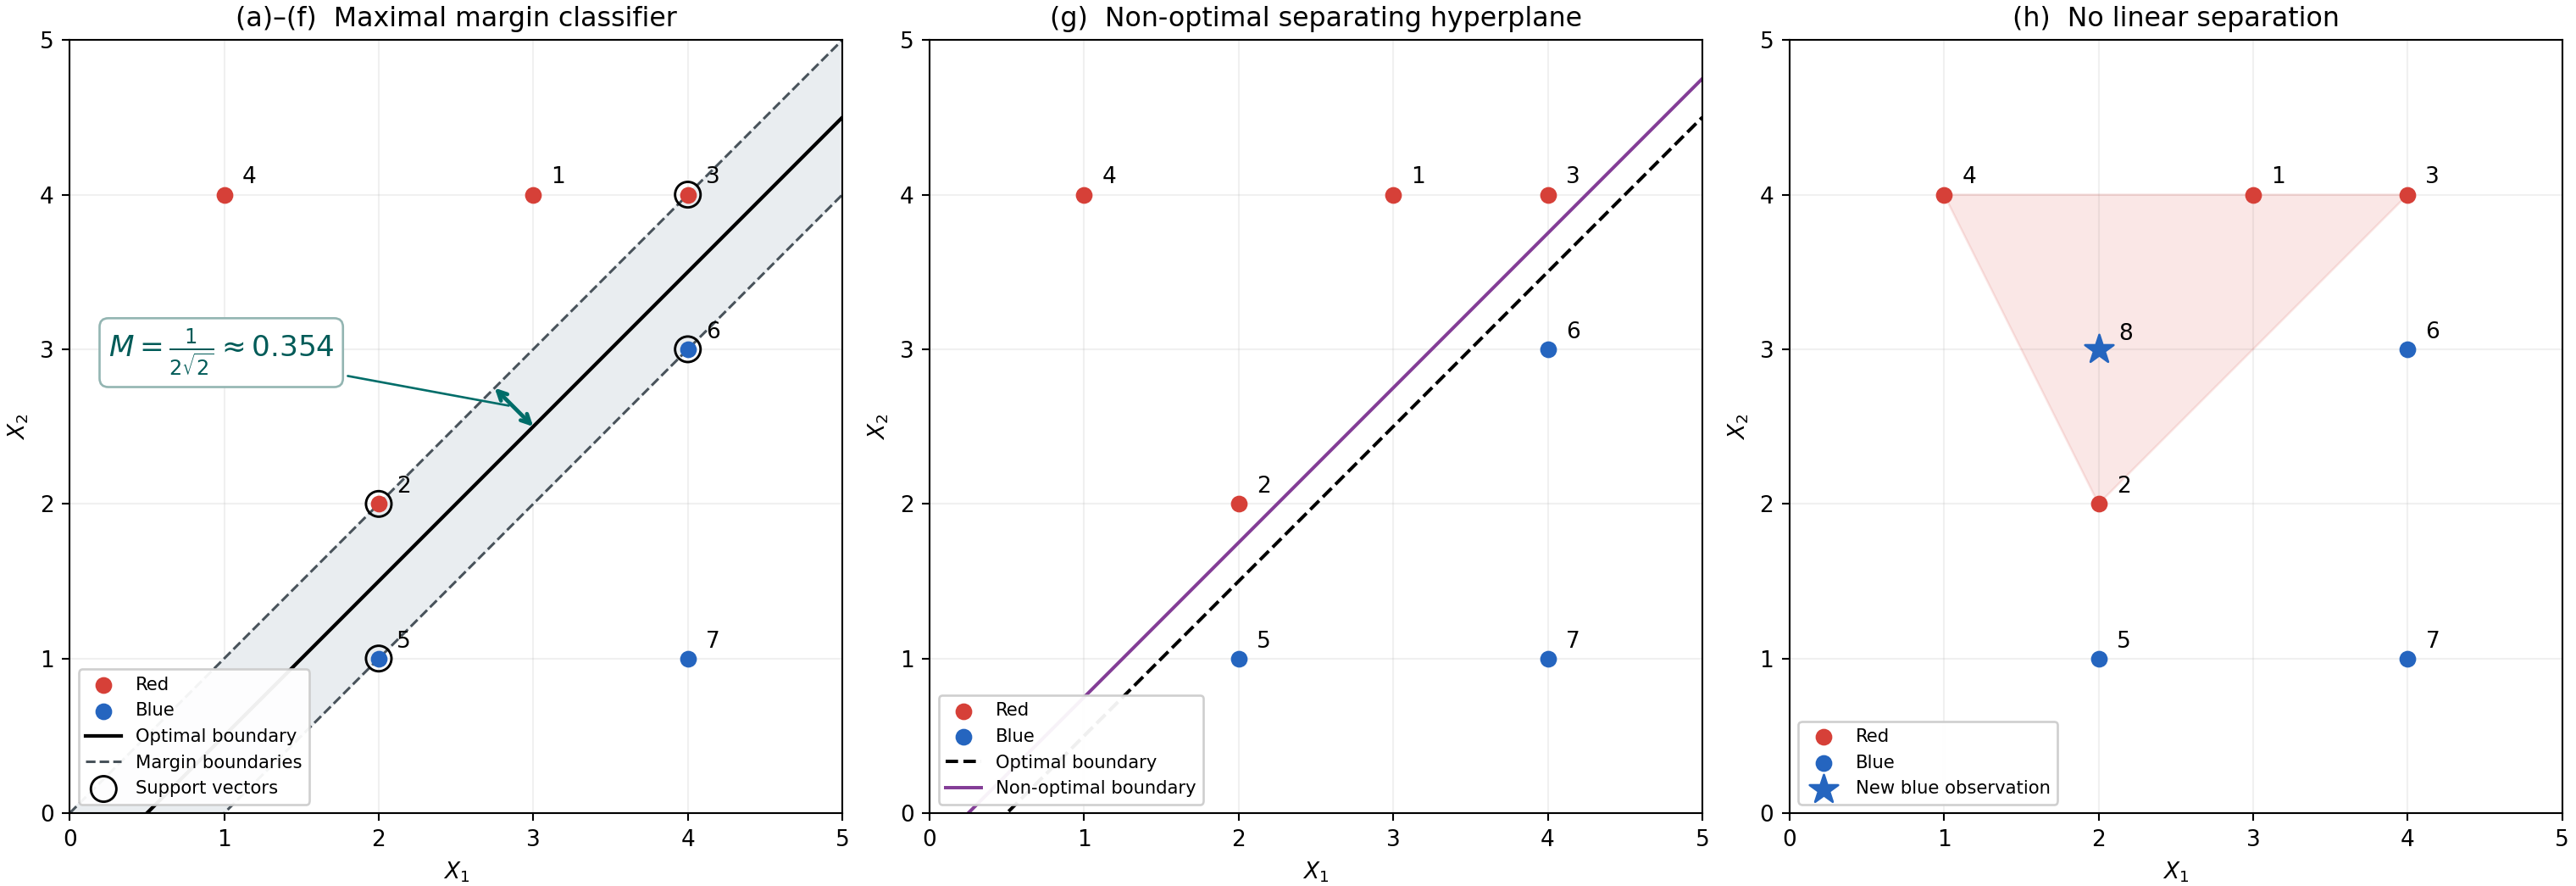
**(a)** The observations are shown in the first plot. Observations 1–4 are Red, and observations 5–7 are Blue.

**(b)** The optimal separating hyperplane:

$$
\frac{1}{2}-X_1+X_2=0.
$$

**(c)** Classify an observation as Red if

$$
\frac{1}{2}-X_1+X_2>0,
$$

and as Blue otherwise. Thus,

$$
\beta_0=\frac{1}{2},\qquad \beta_1=-1,\qquad \beta_2=1.
$$

**(d)** 

The margin is

$$
M=\frac{1/2}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt{2}}
\approx0.3536.
$$


**(e)** The support vectors are observations **2, 3, 5, and 6**:

$$
(2,2),\quad(4,4),\quad(2,1),\quad(4,3).
$$


**(f)** Observation 7, $(4,1)$, is not a support vector. A sufficiently small movement that keeps it outside the margin on the Blue side does not change the optimal separating hyperplane.

**(g)** One non-optimal separating hyperplane is

$$
X_2=X_1-\frac{1}{4}.
$$

It correctly separates the classes, but its minimum distance to the observations is only

$$
\frac{1}{4\sqrt{2}}\approx0.1768,
$$

which is smaller than the optimal margin.

**(h)** Add a Blue observation at $(2,3)$. This point lies inside the triangle formed by Red observations 2, 3, and 4. Therefore, no straight line can separate all Red observations from all Blue observations.